# AG News: pretrained model ranking prediction

Adapted from `Ohsumed/RankPredict.ipynb`. Uses only the local AG News **train** split.
Each article has one of four labels. `document_id` records its original train row;
`labels` contains a singleton list for compatibility with the pairwise statistics.
The test split is reserved. Sampling and metric settings follow the reference notebook.
Bootstrap standard deviations describe different-label score resampling conditional
on the fixed same-label scores, not full document-level uncertainty.


In [11]:
from pathlib import Path
from collections import defaultdict
from itertools import combinations
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_from_disk

# Support running from the project root or the ACGNews directory.
PROJECT_DIR = Path.cwd()
if (PROJECT_DIR / "ACGNews" / "data" / "ag_news").is_dir():
    PROJECT_DIR = PROJECT_DIR / "ACGNews"
DATA_DIR = PROJECT_DIR / "data" / "ag_news"
RESULTS_DIR = PROJECT_DIR / "results" / "rank_prediction"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


In [12]:
dataset = load_from_disk(str(DATA_DIR))
train_dataset = dataset["train"]
label_names = train_dataset.features["label"].names
assert label_names == ["World", "Sports", "Business", "Sci/Tech"]

df = train_dataset.to_pandas()
# IDs refer to original train rows, before cleaning or sampling.
df["document_id"] = [f"ag_news_train_{i:06d}" for i in range(len(df))]
df = df.dropna(subset=["text", "label"]).copy()
df["training_text"] = df["text"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["training_text"].ne("")].copy()
assert df["label"].isin(range(len(label_names))).all()
# Preserve AG News single-label semantics; do not merge conflicting labels.
df["labels"] = df["label"].map(lambda value: [label_names[int(value)]])
print("Repeated normalized texts:", df["training_text"].duplicated().sum())
print("Duplicate texts are retained to preserve the source train dataset.")
training_df = df[["document_id", "training_text", "labels"]].reset_index(drop=True)
assert training_df["document_id"].is_unique
assert training_df["labels"].map(len).eq(1).all()
assert set(training_df["labels"].explode()) == set(label_names)
print("Training documents:", len(training_df))
print("Label counts:")
print(training_df["labels"].explode().value_counts())
display(training_df.head())


Repeated normalized texts: 79
Duplicate texts are retained to preserve the source train dataset.
Training documents: 120000
Label counts:
labels
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


,document_id,training_text,labels
0,ag_news_train_000000,Wall St. Bears Claw Back Into the Black (Reute...,[Business]
1,ag_news_train_000001,Carlyle Looks Toward Commercial Aerospace (Reu...,[Business]
2,ag_news_train_000002,Oil and Economy Cloud Stocks' Outlook (Reuters...,[Business]
3,ag_news_train_000003,Iraq Halts Oil Exports from Main Southern Pipe...,[Business]
4,ag_news_train_000004,"Oil prices soar to all-time record, posing new...",[Business]


In [13]:
TEXT_COL = "training_text"
LABEL_COL = "labels"

SAMPLE_SIZE = 200
RANDOM_SEED = 42
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased"
]

In [14]:
def asymmetry_eta(x, bandwidth=None):
    """
    Estimate eta using Patil et al.-style estimator:
    eta_hat = -Corr(f_hat(X_i), F_hat(X_i))

    f_hat(X_i): leave-one-out Gaussian KDE
    F_hat(X_i): leave-one-out empirical CDF
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)

    if n < 3:
        return np.nan

    # Silverman's bandwidth
    s = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    sigma = min(s, iqr / 1.349) if iqr > 0 else s
    if np.isclose(sigma, 0):
        sigma = s if s > 0 else 1.0
    h = bandwidth if bandwidth is not None else 0.9 * sigma * (n ** (-1 / 5))#calculate bandwidth
    if h <= 0:
        h = 1.06 * (s if s > 0 else 1.0) * (n ** (-1 / 5))

    # Leave-one-out KDE
    diffs = (x[None, :] - x[:, None]) / h#cal culate pairwise difference
    K = stats.norm.pdf(diffs)#fit standardized distance into gaussian kernel
    np.fill_diagonal(K, 0.0)#leave one out
    f_hat = K.sum(axis=1) / ((n - 1) * h)#KED for pdf

    # Leave-one-out empirical CDF
    indicators = (x[None, :] < x[:, None]).astype(float)
    np.fill_diagonal(indicators, 0.0)
    F_hat = indicators.sum(axis=1) / (n - 1)

    if np.std(f_hat, ddof=1) == 0 or np.std(F_hat, ddof=1) == 0:
        return np.nan

    eta = -np.corrcoef(f_hat, F_hat)[0, 1]#calculate correlation

    return eta

In [15]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):

    hist1, bin_edges = np.histogram(dist1, bins=bins, range=value_range)
    hist2, _ = np.histogram(dist2, bins=bin_edges)

    p = hist1 / hist1.sum()
    q = hist2 / hist2.sum()

    chi_dist = 0.5 * np.sum((p - q) ** 2 / (p + q + eps))

    return chi_dist

In [16]:
def create_cosine_similarity_matrix(
    embeddings,
):
    normalized_embeddings = F.normalize(
        embeddings.detach().cpu().float(),
        p=2,
        dim=1,
    )

    similarity_matrix = (
        normalized_embeddings
        @ normalized_embeddings.T
    )

    return similarity_matrix.numpy()

In [17]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [18]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [19]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [20]:
def prepare_sampling_dataframe(
    training_df,
):
    result = training_df[
        [
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    ].copy()

    # Remove missing essential values
    result = result.dropna(
        subset=[
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    )

    # Remove empty text
    result = result[
        result[TEXT_COL]
        .astype(str)
        .str.strip()
        .ne("")
    ].copy()

    # One row per document
    result = result.drop_duplicates(
        subset=["document_id"],
        keep="first",
    )

    # Character count: descriptive only
    result["char_length"] = (
        result[TEXT_COL]
        .str.len()
    )

    # Word count: used for quantile sampling
    result["length"] = (
        result[TEXT_COL]
        .str.split()
        .str.len()
    )

    result = result.reset_index(
        drop=True
    )

    print(
        "Shape:",
        result.shape,
    )

    print(
        "Minimum word count:",
        result["length"].min(),
    )

    print(
        "Average word count:",
        result["length"].mean(),
    )

    print(
        "Maximum word count:",
        result["length"].max(),
    )

    print(
        "Number of labels:",
        result[LABEL_COL]
        .explode()
        .nunique(),
    )

    return result

In [21]:
sampling_df = (
    prepare_sampling_dataframe(
        training_df
    )
)

Shape: (120000, 5)
Minimum word count: 8
Average word count: 37.84745
Maximum word count: 177
Number of labels: 4


In [22]:
def sample_from_length_groups(
    df,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
    text_col="training_text",
):
    sampling_pool = (
        df.copy()
        .reset_index(drop=True)
    )

    if sample_size > len(sampling_pool):
        raise ValueError(
            f"sample_size={sample_size} exceeds "
            f"dataset size={len(sampling_pool)}"
        )

    # Calculate word count if it does not exist
    if "length" not in sampling_pool.columns:
        sampling_pool["length"] = (
            sampling_pool[text_col]
            .astype(str)
            .str.split()
            .str.len()
        )

    # The actual number of groups cannot exceed:
    # 1. requested quantiles
    # 2. sample size
    # 3. number of unique text lengths
    effective_quantiles = min(
        num_quantiles,
        sample_size,
        sampling_pool["length"].nunique(),
    )

    # Create length groups from the whole dataset
    sampling_pool["_length_group"] = pd.qcut(
        sampling_pool["length"],
        q=effective_quantiles,
        labels=False,
        duplicates="drop",
    )

    number_of_groups = (
        sampling_pool["_length_group"]
        .nunique()
    )

    samples_per_group = (
        sample_size // number_of_groups
    )

    sampled_parts = []

    # Sample approximately the same number
    # from every length group
    for group_number, group_df in (
        sampling_pool.groupby(
            "_length_group",
            observed=True,
        )
    ):
        number_to_sample = min(
            samples_per_group,
            len(group_df),
        )

        sampled_part = group_df.sample(
            n=number_to_sample,
            random_state=(
                random_seed
                + int(group_number)
            ),
        )

        sampled_parts.append(
            sampled_part
        )

    sampled_df = pd.concat(
        sampled_parts,
        axis=0,
    )

    # Fill remaining positions if qcut produced
    # fewer groups or some groups were too small
    remaining_count = (
        sample_size - len(sampled_df)
    )

    if remaining_count > 0:
        remaining_pool = (
            sampling_pool.drop(
                index=sampled_df.index
            )
        )

        additional_samples = (
            remaining_pool.sample(
                n=remaining_count,
                random_state=random_seed,
            )
        )

        sampled_df = pd.concat(
            [
                sampled_df,
                additional_samples,
            ],
            axis=0,
        )

    # Shuffle the final sample
    sampled_df = (
        sampled_df
        .sample(
            frac=1,
            random_state=random_seed,
        )
        .drop(
            columns=["_length_group"]
        )
        .reset_index(drop=True)
    )

    print(
        "Original dataset size:",
        len(sampling_pool),
    )
    print(
        "Actual sample size:",
        len(sampled_df),
    )
    print(
        "Minimum word count:",
        sampled_df["length"].min(),
    )
    print(
        "Average word count:",
        sampled_df["length"].mean(),
    )
    print(
        "Maximum word count:",
        sampled_df["length"].max(),
    )
    print(
        "Number of represented labels:",
        sampled_df["labels"]
        .explode()
        .nunique(),
    )

    return sampled_df

In [23]:
sampled_df = sample_from_length_groups(
    df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED,
    text_col=TEXT_COL,
)

Original dataset size: 120000
Actual sample size: 200
Minimum word count: 14
Average word count: 39.285
Maximum word count: 91
Number of represented labels: 4


In [24]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [25]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = same_scores.mean()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = sampled_diff_scores.mean()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [26]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # AG News text and singleton label lists
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["World"], ["Sports"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
            sampled_df["document_id"]
            .tolist()
        ),

        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [27]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
):
    if models is None:
        models = MODELS

    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=grouped_df,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                ),
                text_col=text_col,
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [28]:
results = metric_collect(
    grouped_df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    num_repetitions=3,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
)

Repetition 1/3
Repetition seed: 383329927
Original dataset size: 120000
Actual sample size: 200
Minimum word count: 14
Average word count: 39.09
Maximum word count: 81
Number of represented labels: 4
Actual sample size: 200
Label counts:
labels
Business    49
Sci/Tech    53
Sports      40
World       58
Name: count, dtype: int64
Number of represented labels: 4

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: google-bert/bert-base-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 4987
Number of label-set pair types: 6
Total unique between-label document pairs: 14913
Same-label target size: 4987
Different-label pair types: 6
Base sample per diff-label pair: 831

Summary:
Same mean: 0.7063516172170878
Different mean: 0.6516280896883105
Mean gap: 0.054723527528777384
Same eta: -0.23885205597203038
Different eta: -0.13748737170032826
Different |eta|: 0.13748737170032826
Eta gap: -0.10136468427170214
Chi-square distance: 0.15281774341698226
Chi-square bootstrap std: 0.004030381665743997

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (54 outputs left out)

Model: recobo/agriculture-bert-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 5047
Number of label-set pair types: 6
Total unique between-label document pairs: 14853
Same-label target size: 5047
Different-label pair types: 6
Base sample per diff-label pair: 841

Summary:
Same mean: 0.8595956397193575
Different mean: 0.8414480874278131
Mean gap: 0.018147552291544376
Same eta: -0.24083606124073018
Different eta: -0.30108488419674106
Different |eta|: 0.30108488419674106
Eta gap: 0.0602488229560109
Chi-square distance: 0.06403245889451495
Chi-square bootstrap std: 0.0031917329387478924

Running model: recobo/chemical-bert-uncased


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: recobo/chemical-bert-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 5047
Number of label-set pair types: 6
Total unique between-label document pairs: 14853
Same-label target size: 5047
Different-label pair types: 6
Base sample per diff-label pair: 841

Summary:
Same mean: 0.8954345101480652
Different mean: 0.891117537845355
Mean gap: 0.004316972302710222
Same eta: -0.4175305528635041
Different eta: -0.3798619136603509
Different |eta|: 0.3798619136603509
Eta gap: -0.03766863920315325
Chi-square distance: 0.009872955335617334
Chi-square bootstrap std: 0.0013256833390034926


In [29]:
summary_df = results[
    "summary_df"
]

display(summary_df)

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,n_bootstrap,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels
0,google-bert/bert-base-uncased,0.706352,-0.238852,0.238852,4987,0.651628,0.000827,-0.137487,0.020878,0.137487,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,4
1,allenai/scibert_scivocab_uncased,0.838681,-0.183557,0.183557,4987,0.820671,0.000486,-0.130880,0.020453,0.130880,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,4
2,nlpaueb/legal-bert-base-uncased,0.897815,-0.260684,0.260684,4987,0.886166,0.000332,-0.212862,0.022564,0.212862,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,4
3,ahmedrachid/FinancialBERT,0.817749,-0.221317,0.221317,4987,0.796480,0.000671,-0.179964,0.021714,0.179964,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,4
4,Lianglab/PharmBERT-uncased,0.763678,-0.288613,0.288613,4987,0.738211,0.000750,-0.207081,0.020667,0.207081,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,4
5,recobo/agriculture-bert-uncased,0.862313,-0.261656,0.261656,4987,0.845297,0.000461,-0.212205,0.022041,0.212205,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,4
6,recobo/chemical-bert-uncased,0.896894,-0.389674,0.389674,4987,0.891502,0.000391,-0.314960,0.023332,0.314960,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,4
7,google-bert/bert-base-uncased,0.706019,-0.121266,0.121266,4918,0.660015,0.000838,-0.146394,0.021120,0.146394,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,4
8,allenai/scibert_scivocab_uncased,0.840801,-0.283214,0.283214,4918,0.821961,0.000509,-0.229040,0.021595,0.229040,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,4
9,nlpaueb/legal-bert-base-uncased,0.900151,-0.329872,0.329872,4918,0.888046,0.000315,-0.226633,0.022131,0.226633,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,4


In [30]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)

,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.768791,0.004689,0.741618,0.002999,0.000767,-0.295822,0.018942,0.295822,0.018942,...,0.021526,0.053120,0.026972,0.063083,0.003557,0.003175,4984.0,4984.0,4.0,3
1,ahmedrachid/FinancialBERT,0.820141,0.005409,0.798436,0.005477,0.000686,-0.259421,0.049121,0.259421,0.049121,...,0.022464,0.044665,0.026641,0.052578,0.005369,0.002918,4984.0,4984.0,4.0,3
2,allenai/scibert_scivocab_uncased,0.837772,0.003573,0.819612,0.003022,0.000503,-0.220195,0.054817,0.220195,0.054817,...,0.020500,0.055165,0.002984,0.061657,0.005546,0.003003,4984.0,4984.0,4.0,3
3,google-bert/bert-base-uncased,0.705058,0.001959,0.654469,0.004804,0.000842,-0.172990,0.060055,0.172990,0.060055,...,0.021235,0.049879,0.044744,0.134036,0.017022,0.003966,4984.0,4984.0,4.0,3
4,nlpaueb/legal-bert-base-uncased,0.897810,0.002344,0.885142,0.003530,0.000337,-0.275395,0.048813,0.275395,0.048813,...,0.021422,0.077920,0.027820,0.059070,0.009731,0.003029,4984.0,4984.0,4.0,3
5,recobo/agriculture-bert-uncased,0.862673,0.003272,0.844903,0.003276,0.000467,-0.287060,0.062900,0.287060,0.062900,...,0.021026,0.066868,0.021369,0.066239,0.006788,0.003198,4984.0,4984.0,4.0,3
6,recobo/chemical-bert-uncased,0.897586,0.002568,0.892681,0.002383,0.000388,-0.410715,0.018595,0.410715,0.018595,...,0.022049,0.065414,0.023966,0.011152,0.001132,0.001426,4984.0,4984.0,4.0,3


In [31]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,6,2,2,2,2,4,5,3
1,ahmedrachid/FinancialBERT,5,3,3,3,5,5,7,6
2,allenai/scibert_scivocab_uncased,4,4,4,4,6,6,4,4
3,google-bert/bert-base-uncased,7,1,1,1,7,7,6,1
4,nlpaueb/legal-bert-base-uncased,1,6,6,6,4,3,1,5
5,recobo/agriculture-bert-uncased,3,5,5,5,3,2,2,2
6,recobo/chemical-bert-uncased,2,7,7,7,1,1,3,7


In [32]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
ranking_path = PROJECT_DIR / "results" / "ag_news_5fold" / "ag_news_real_model_ranking.csv"
real_ranking_df = pd.read_csv(ranking_path)
assert real_ranking_df["model"].is_unique
real_rank_map = dict(zip(real_ranking_df["model"], real_ranking_df["real_rank"]))
assert set(MODELS).issubset(real_rank_map)
selected_real_ranks = [1, 2, 4, 6, 7]
selected_models = sorted(
    [name for name in MODELS if real_rank_map[name] in selected_real_ranks],
    key=real_rank_map.get,
)
display(real_ranking_df)


,real_rank,model,completed_folds,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,training_hours_total
0,1,google-bert/bert-base-uncased,5,0.947375,0.001030,0.947388,0.001008,0.947375,0.001030,1.200185
1,2,Lianglab/PharmBERT-uncased,5,0.945400,0.000941,0.945411,0.000931,0.945400,0.000941,1.191728
2,3,allenai/scibert_scivocab_uncased,5,0.942642,0.002091,0.942653,0.002073,0.942642,0.002091,1.270295
3,4,recobo/agriculture-bert-uncased,5,0.942525,0.001233,0.942519,0.001233,0.942525,0.001233,1.241469
4,5,nlpaueb/legal-bert-base-uncased,5,0.941858,0.001328,0.941838,0.001302,0.941858,0.001328,1.247366
5,6,recobo/chemical-bert-uncased,5,0.932142,0.000756,0.932110,0.000744,0.932142,0.000756,1.241426
6,7,ahmedrachid/FinancialBERT,5,0.927758,0.001433,0.927720,0.001455,0.927758,0.001433,1.279269


In [34]:
distribution_data = {}

for model_name in selected_models:
    same_score_parts = []
    diff_score_parts = []

    for repetition in range(1, 4):
        model_result = results[
            "full_results"
        ][
            (
                repetition,
                model_name,
            )
        ]

        same_score_parts.append(
            np.asarray(
                model_result[
                    "same_scores"
                ],
                dtype=float,
            )
        )

        diff_score_parts.append(
            np.asarray(
                model_result[
                    "diff_scores_original"
                ],
                dtype=float,
            )
        )

    # Combine the three repetitions
    same_scores = np.concatenate(
        same_score_parts
    )

    diff_scores = np.concatenate(
        diff_score_parts
    )

    distribution_data[
        model_name
    ] = {
        "real_rank":
            real_rank_map[model_name],

        "same_scores":
            same_scores,

        "diff_scores":
            diff_scores,

        "same_mean":
            same_scores.mean(),

        "diff_mean":
            diff_scores.mean(),
    }

In [35]:
for model_name, values in (
    distribution_data.items()
):
    print(
        model_name,
        "| rank:",
        values["real_rank"],
        "| same:",
        len(values["same_scores"]),
        "| different:",
        len(values["diff_scores"]),
    )

google-bert/bert-base-uncased | rank: 1 | same: 14952 | different: 44748
Lianglab/PharmBERT-uncased | rank: 2 | same: 14952 | different: 44748
recobo/agriculture-bert-uncased | rank: 4 | same: 14952 | different: 44748
recobo/chemical-bert-uncased | rank: 6 | same: 14952 | different: 44748
ahmedrachid/FinancialBERT | rank: 7 | same: 14952 | different: 44748


In [36]:
rank_colours = {}

for real_rank in range(1, 8):
    # Rank 1 gets the darkest red.
    # Rank 7 remains light but visible.
    colour_position = np.interp(
        real_rank,
        [1, 7],
        [0.90, 0.35],
    )

    rank_colours[real_rank] = (
        plt.cm.Reds(
            colour_position
        )
    )

In [37]:
all_plot_scores = []

for values in distribution_data.values():
    all_plot_scores.append(
        values["same_scores"]
    )
    all_plot_scores.append(
        values["diff_scores"]
    )

all_plot_scores = np.concatenate(
    all_plot_scores
)

display_minimum = max(
    -1,
    np.quantile(
        all_plot_scores,
        0.001,
    ) - 0.01,
)

display_maximum = min(
    1,
    np.quantile(
        all_plot_scores,
        0.999,
    ) + 0.01,
)

print(
    "Display range:",
    display_minimum,
    display_maximum,
)

Display range: 0.4703106424808502 0.9591300703287123


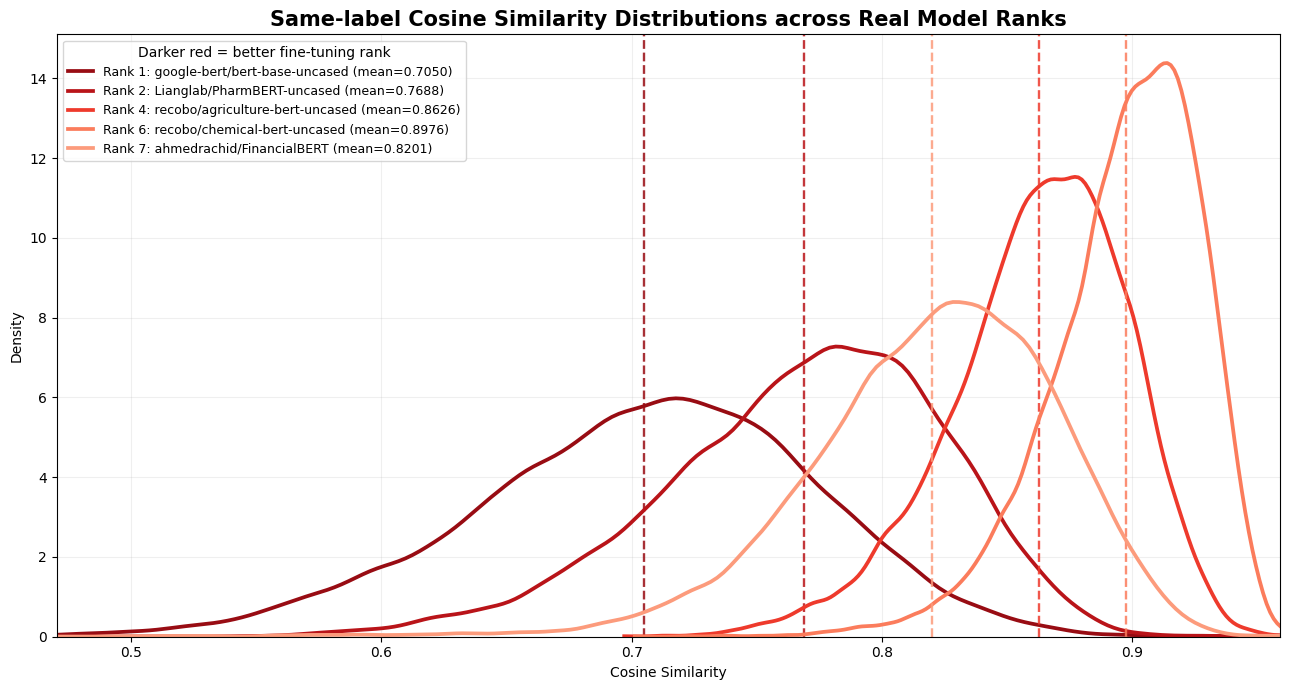

In [38]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "same_scores"
    ]

    mean_value = values[
        "same_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Same-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker red = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ag_news_same_label_rank_spanning.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

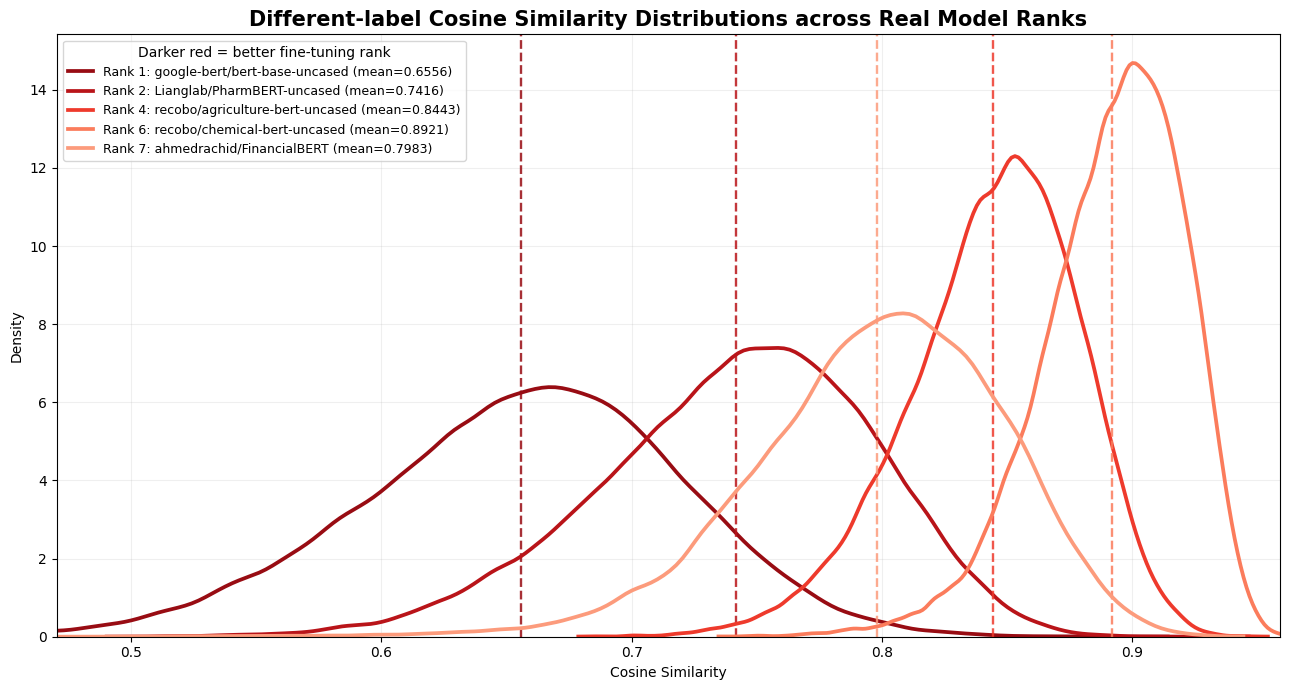

In [39]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "diff_scores"
    ]

    mean_value = values[
        "diff_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Different-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker red = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    (
        RESULTS_DIR / "ag_news_different_label_rank_spanning.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [40]:
def predict_model_ranking(metric_summary_df):
    # RankPredict 的列名，以及 grid search 得到的系数
    coefficients = {
        "same_mean_mean": -0.2,
        "diff_mean_mean": 0.2,
        "same_abs_eta_mean": -0.4,
        "diff_abs_eta_mean": 0.1,
        "chi2_distance_mean": -0.1,
    }

    result = metric_summary_df.copy()
    metrics = list(coefficients)

    # 在当前数据集的候选模型之间进行 Z-score 标准化
    values = result[metrics]
    std = values.std(ddof=0)

    scaled = (
        (values - values.mean())
        / std.mask(np.isclose(std, 0), 1.0)
    )

    # 线性组合：Score = Σ coefficient × standardized metric
    result["PredictionScore"] = (
        scaled.mul(pd.Series(coefficients))
        .sum(axis=1)
        .round(12)
    )

    result["PredictedRank"] = result["PredictionScore"].rank(
        ascending=False,
        method="average",
    )

    return result[
        ["model", "PredictionScore", "PredictedRank"]
    ].sort_values("PredictedRank")

In [41]:
predicted_ranking = predict_model_ranking(metric_summary_df)
display(predicted_ranking)

,model,PredictionScore,PredictedRank
2,allenai/scibert_scivocab_uncased,0.264909,1.0
3,google-bert/bert-base-uncased,0.215212,2.0
1,ahmedrachid/FinancialBERT,0.087460,3.0
4,nlpaueb/legal-bert-base-uncased,0.020811,4.0
5,recobo/agriculture-bert-uncased,-0.049763,5.0
0,Lianglab/PharmBERT-uncased,-0.098675,6.0
6,recobo/chemical-bert-uncased,-0.439954,7.0
